# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1056 acc 0.458 | val loss 0.9236 acc 0.570 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9563 acc 0.519 | val loss 0.8604 acc 0.489 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9018 acc 0.530 | val loss 0.7984 acc 0.601 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.8796 acc 0.519 | val loss 0.8262 acc 0.582


...

[ResNet-18 (scratch)] Epoch  29/100 | LR: 1.00e-05 | train loss 0.4439 acc 0.791 | val loss 0.5019 acc 0.786


[ResNet-18 (scratch)] Epoch  30/100 | LR: 1.00e-06 | train loss 0.4338 acc 0.788 | val loss 0.5188 acc 0.786


[ResNet-18 (scratch)] Epoch  31/100 | LR: 1.00e-06 | train loss 0.3967 acc 0.803 | val loss 0.5121 acc 0.780


[ResNet-18 (scratch)] Epoch  32/100 | LR: 1.00e-06 | train loss 0.4436 acc 0.778 | val loss 0.5167 acc 0.802


[ResNet-18 (scratch)] Epoch  33/100 | LR: 1.00e-06 | train loss 0.4128 acc 0.803 | val loss 0.4978 acc 0.802

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 33.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4927)


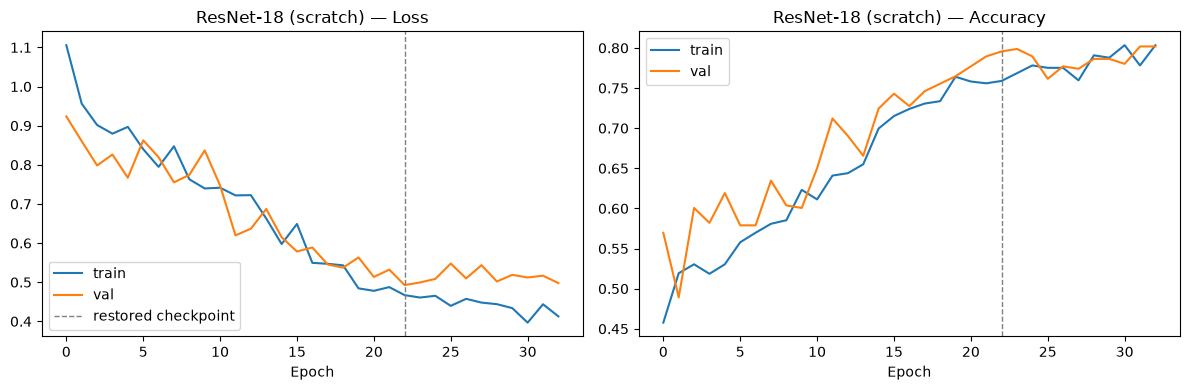

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.713


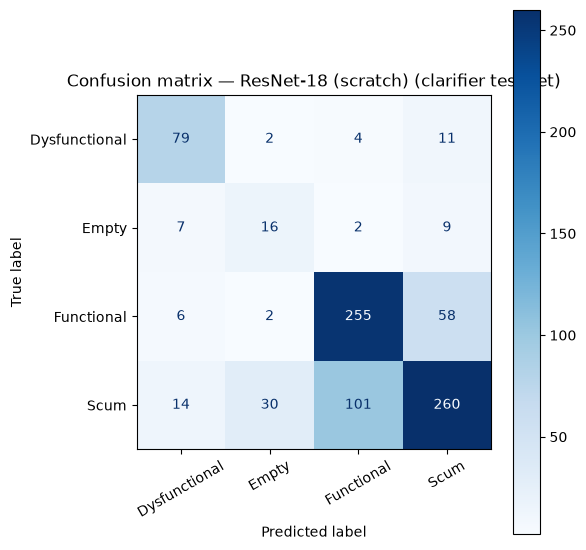

               precision    recall  f1-score   support

Dysfunctional      0.745     0.823     0.782        96
        Empty      0.320     0.471     0.381        34
   Functional      0.704     0.794     0.747       321
         Scum      0.769     0.642     0.700       405

     accuracy                          0.713       856
    macro avg      0.635     0.682     0.652       856
 weighted avg      0.724     0.713     0.714       856



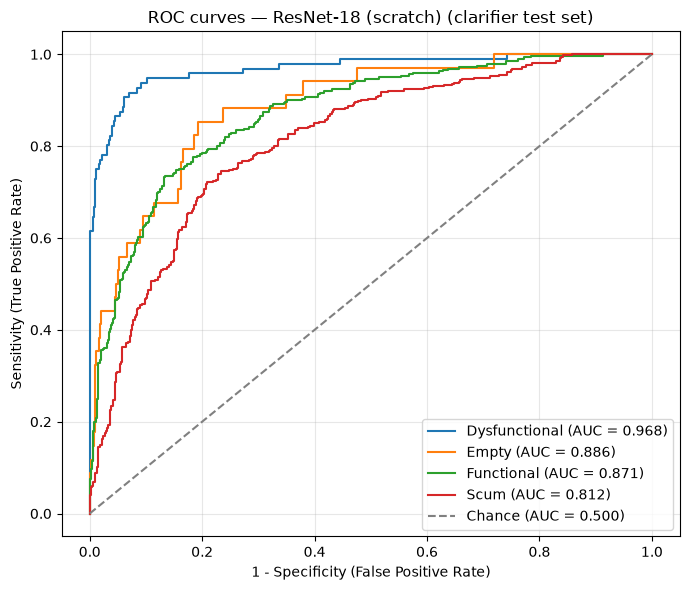

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.968
  Empty          : 0.886
  Functional     : 0.871
  Scum           : 0.812

Mean AUC (over 4/4 classes with test examples): 0.884


(np.float64(0.7126168224299065),
 {'Dysfunctional': 0.9684484649122808,
  'Empty': 0.886002576212967,
  'Functional': 0.871161964654846,
  'Scum': 0.8119624428567518})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/results_clarifier_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/clarifier_resnet18_scratch_cnn.pt
